# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [18]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Боднар Денис'     # прізвище та ім'я
GROUP        = 'ШІ-33'            # шифр групи
NUMBER       = 1                  # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Боднар Денис | ШІ-33 | номер 1


In [19]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 1   ·   Боднар Денис   ·   ШІ-33

   Ринок:  Odesa
   Товар:  хліб пшеничний   (у наборі даних: Bread (wheat) - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [20]:
import warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display

warnings.simplefilter('ignore')
plt.rcParams.update({'figure.figsize': (11, 3.8), 'axes.grid': True, 'grid.alpha': .25})

prices = pd.read_csv('ціни_україна_2014_2017.csv')
prices['date'] = pd.to_datetime(dict(year=prices['рік'], month=prices['місяць'], day=1))

GRID = pd.date_range('2014-03-01', '2017-12-01', freq='MS') 
raw = (prices[(prices['ринок'] == MARKET) & (prices['товар'] == GOOD)]
       .set_index('date')['ціна'].sort_index())

print('Рядків для мого варіанта в наборі:', len(raw), '| з них порожніх (NaN):', int(raw.isna().sum()))
print('Якщо рахувати лише isna() без сітки, пропусків «немає» — саме так помилився колега в завданні 9\n')

s_gap = raw.reindex(GRID)
gaps = s_gap.index[s_gap.isna()]
print('Місяців у сітці:', len(GRID), '| з виміром:', int(s_gap.notna().sum()))
print('Пропуск(и):', [d.strftime('%m.%Y') for d in gaps])

rows_by_month = prices.groupby('date').size().reindex(GRID, fill_value=0)
print('\nКількість рядків у всьому наборі за місяць:')
print(rows_by_month['2017-06':'2017-10'].to_string())
print('Місяців без жодного рядка в усьому наборі:', [d.strftime('%m.%Y') for d in rows_by_month.index[rows_by_month == 0]])

months_per_series = prices.groupby(['ринок', 'товар']).date.nunique()
print('\nСкільки місяців мають ряди (ринок × товар) — кількість таких рядів:')
print(months_per_series.value_counts().sort_index().to_string())

Рядків для мого варіанта в наборі: 45 | з них порожніх (NaN): 0
Якщо рахувати лише isna() без сітки, пропусків «немає» — саме так помилився колега в завданні 9

Місяців у сітці: 46 | з виміром: 45
Пропуск(и): ['08.2017']

Кількість рядків у всьому наборі за місяць:
2017-06-01    650
2017-07-01    650
2017-08-01      0
2017-09-01    650
2017-10-01    650
Freq: MS
Місяців без жодного рядка в усьому наборі: ['08.2017']

Скільки місяців мають ряди (ринок × товар) — кількість таких рядів:
date
1      25
2      25
11      1
40     25
42     25
45    599


**Висновок до завдання 1:**

1. У сітці 03.2014–12.2017 рівно **46 місяців**, виміри є у **45**.
2. Пропуск — **серпень 2017**.
3. Чому він виник: у всьому наборі за серпень 2017 **немає жодного рядка** (за червень, липень, вересень і жовтень по 650). Тобто серпня немає ні в одного ринку й ні в одного товару, це дірка в самому наборі, а не особливість Одеси чи хліба. Чому саме серпня — у файлі не сказано, тож точну причину я назвати не можу (схоже на пропущений цикл збору даних). У моєму ряді пропуск **один**. Інші «пропуски» набору — це інша історія: Крим (1 місяць), Севастополь (2), Луганська (40) і Донецька (42) просто випали з спостережень.

Окремо помітив: `isna()` на ряді без сітки показує 0 пропусків, бо рядка за серпень не існує взагалі. Дірка видна тільки після `reindex` на повну місячну сітку. Саме на цьому помилився колега в завданні 9.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

Сусіди пропуску: липень 2017 = 9.46, вересень 2017 = 9.46

Яке значення дає кожен спосіб для 08.2017:
перенесення останнього (ffill)    9.460
лінійна                           9.460
кубічна                           9.087
минулорічне значення (08.2016)    9.500


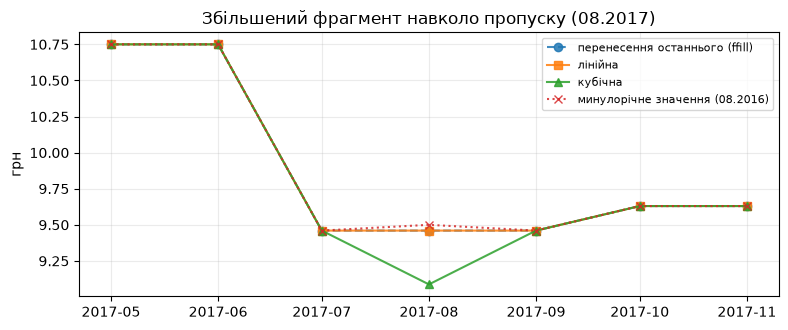


Фінальний ряд: 46 точок, пропусків: 0

Ринки з найменшим покриттям:


,перший,останній,місяців
ринок,,,
Crimea,2014-03-01,2014-03-01,1
m. Sevastopol,2014-03-01,2014-04-01,2
Luhanska,2014-03-01,2017-12-01,40
Donetska,2014-03-01,2017-12-01,42
Zhytomyr,2014-03-01,2017-12-01,45


In [21]:
G = pd.Timestamp('2017-08-01')
before, after = s_gap[G - pd.offsets.MonthBegin(1)], s_gap[G + pd.offsets.MonthBegin(1)]

fills = pd.DataFrame({
    'перенесення останнього (ffill)': s_gap.ffill(),
    'лінійна': s_gap.interpolate('linear'),
    'кубічна': s_gap.interpolate('cubic'),
})
fills['минулорічне значення (08.2016)'] = s_gap.where(s_gap.notna(), s_gap.shift(12))

print(f'Сусіди пропуску: липень 2017 = {before}, вересень 2017 = {after}')
print('\nЯке значення дає кожен спосіб для 08.2017:')
print(fills.loc[G].round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 3.4))
zoom = slice('2017-05-01', '2017-11-01')
for c, st in zip(fills.columns, ['o--', 's-', '^-', 'x:']):
    ax.plot(fills.loc[zoom, c].index, fills.loc[zoom, c].values, st, label=c, alpha=.85)
ax.set_title('Збільшений фрагмент навколо пропуску (08.2017)'); ax.set_ylabel('грн'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

s = s_gap.interpolate('linear')
s.index.freq = 'MS'
s.name = 'price'
print('\nФінальний ряд:', len(s), 'точок, пропусків:', int(s.isna().sum()))

cover = prices.groupby('ринок').date.agg(перший='min', останній='max', місяців='nunique').sort_values('місяців')
print('\nРинки з найменшим покриттям:')
display(cover.head(5))

**Висновок до завдання 2:**

| Спосіб | Значення за 08.2017, грн |
|---|---|
| перенесення останнього | 9,460 |
| лінійна інтерполяція | 9,460 |
| кубічна інтерполяція | 9,087 |
| минулорічне значення (08.2016) | 9,500 |

Сусіди пропуску (липень і вересень) однакові — по 9,46 грн, тому перенесення й лінійна дають те саме число.

**Обрав лінійну інтерполяцію.** Тут вона збігається з перенесенням, але лінійна безпечніша загалом (не відстає на ступінь, коли сусіди різні), а головне — така сама опція «Linear interpolation» є у віджеті Interpolate в Orange, тож Python і Orange заповнять пропуск однаково. Кубічну відкинув: вона дає 9,09 — нижче за обох сусідів, тобто «ціну», якої між двома однаковими значеннями не було. Минулорічне значення (9,50) припускає, що рік повторюється, а сезонність я довести не зміг (завдання 4).

**Коли заповнювати не можна:** коли «пропуск» — не випадкова відсутність виміру, а те, що територію перестали спостерігати. У цьому наборі так з Кримом (є лише 03.2014), Севастополем (2 місяці), Луганською (40 із 46) і Донецькою (42 із 46). Якщо там «заповнити» ціни інтерполяцією, ми вигадаємо ціни на ринках, де їх ніхто не вимірював. Те саме з довгим пропуском або пропуском просто на стрибку ціни — інтерполяція замаже саме те, що цікаво.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

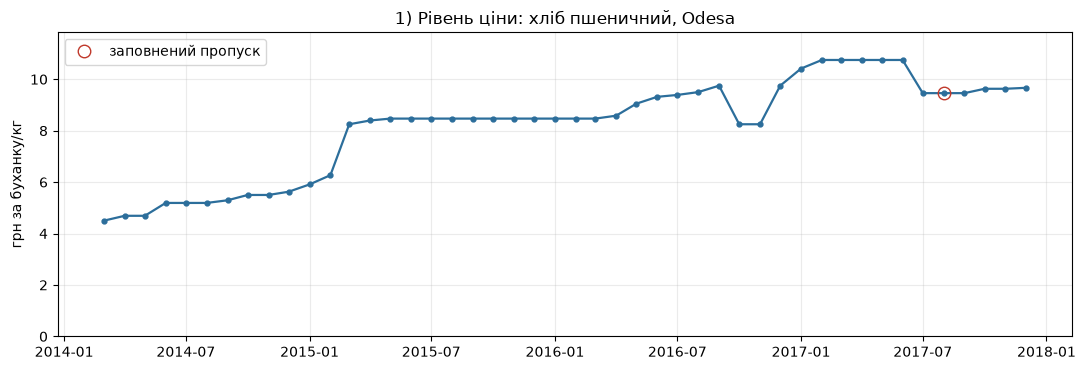

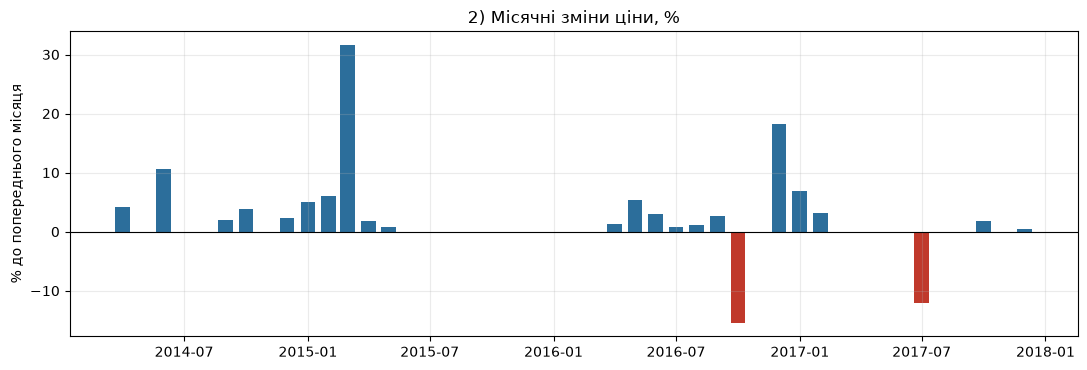

Місяців без зміни ціни (|Δ| < 0.005 грн): 22 із 45 (серед них 1 — штучний, заповнений)
Найбільший місячний приріст: 31.6% у 03.2015
Найбільше падіння:          -15.4% у 10.2016
Найдовша «полиця» без змін: 10 міс. підряд


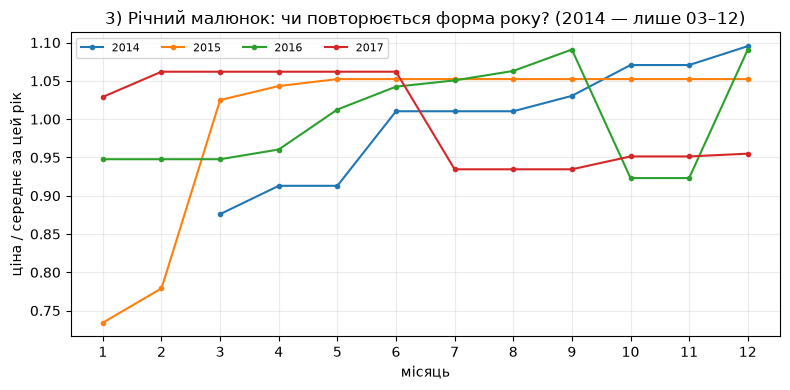

In [22]:
pct = s.pct_change() * 100
filled = pd.Series(s_gap.isna().values, index=s.index)

fig, ax = plt.subplots()
ax.plot(s.index, s.values, '-o', ms=3.5, lw=1.6, color='#2C6E9B')
ax.plot(s.index[filled], s[filled], 'o', ms=9, mfc='none', mec='#C0392B', label='заповнений пропуск')
ax.set_ylim(0, s.max() * 1.1); ax.set_ylabel('грн за буханку/кг')
ax.set_title(f'1) Рівень ціни: {GOOD_UA}, {MARKET}'); ax.legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots()
cols = np.where(pct >= 0, '#2C6E9B', '#C0392B')
ax.bar(pct.index, pct.values, width=22, color=cols)
ax.axhline(0, color='k', lw=.8); ax.set_ylabel('% до попереднього місяця')
ax.set_title('2) Місячні зміни ціни, %')
plt.tight_layout(); plt.show()
print('Місяців без зміни ціни (|Δ| < 0.005 грн):', int((s.diff().abs() < 0.005).sum()), 'із', len(s) - 1,
      '(серед них 1 — штучний, заповнений)')
print('Найбільший місячний приріст: %.1f%% у %s' % (pct.max(), pct.idxmax().strftime('%m.%Y')))
print('Найбільше падіння:          %.1f%% у %s' % (pct.min(), pct.idxmin().strftime('%m.%Y')))
longest = (s.diff().abs() < 0.005).astype(int)
runs = longest.groupby((longest != longest.shift()).cumsum()).sum()
print('Найдовша «полиця» без змін:', int(runs.max()), 'міс. підряд')

fig, ax = plt.subplots(figsize=(8, 4))
for y, g in s.groupby(s.index.year):
    ax.plot(g.index.month, g.values / g.mean(), '-o', ms=3, label=str(y))
ax.set_xticks(range(1, 13)); ax.set_xlabel('місяць'); ax.set_ylabel('ціна / середнє за цей рік')
ax.set_title('3) Річний малюнок: чи повторюється форма року? (2014 — лише 03–12)'); ax.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

**Висновок до завдання 3:**

**Графік 1 — рівень ціни.** Питання: як змінювався рівень і де були злами. Лінія з маркерами: час впорядкований, а маркери нагадують, що це 46 окремих місячних вимірів (заповнений серпень обведено). Шкала лінійна й **від нуля**, щоб подвоєння ціни (з 4,50 до 9,67 грн, пік 10,75) виглядало як подвоєння, а не як зліт.

**Графік 2 — місячні зміни, %.** Питання: як часто ціна взагалі змінюється й наскільки. Стовпчики від нульової лінії: кожна зміна — окрема подія, а знак видно за напрямком і кольором. Шкала лінійна, бо відсоткові зміни бувають від'ємними (логарифм тут не підходить).

**Графік 3 — накладення років по місяцях.** Питання: чи повторюється форма року. Окрема лінія на рік, по осі X — місяць, щоб рік можна було зіставляти з роком; значення поділено на середнє за відповідний рік, бо рівень різних років відрізняється вдвічі. Спільного піку чи западини в одні й ті самі місяці різних років не видно: 2014 росте, 2015 стрибає в березні й стоїть, 2016 росте до вересня й падає, 2017 падає в липні.

**Несподівана знахідка:** ціна на хліб — це «сходинки», а не плавна крива. У **22 із 45** місячних змін ціна не змінилася взагалі (один з цих нулів — мій заповнений серпень), найдовша «полиця» — **10 місяців** поспіль (8,47 грн з червня 2015 по березень 2016), а потім різкі стрибки: **+31,6%** у березні 2015, **−15,4%** у жовтні 2016 і **+18,2%** у грудні 2016. Для ринкової ціни на пшеничний хліб такі падіння на 15% і повернення назад виглядають дивно.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

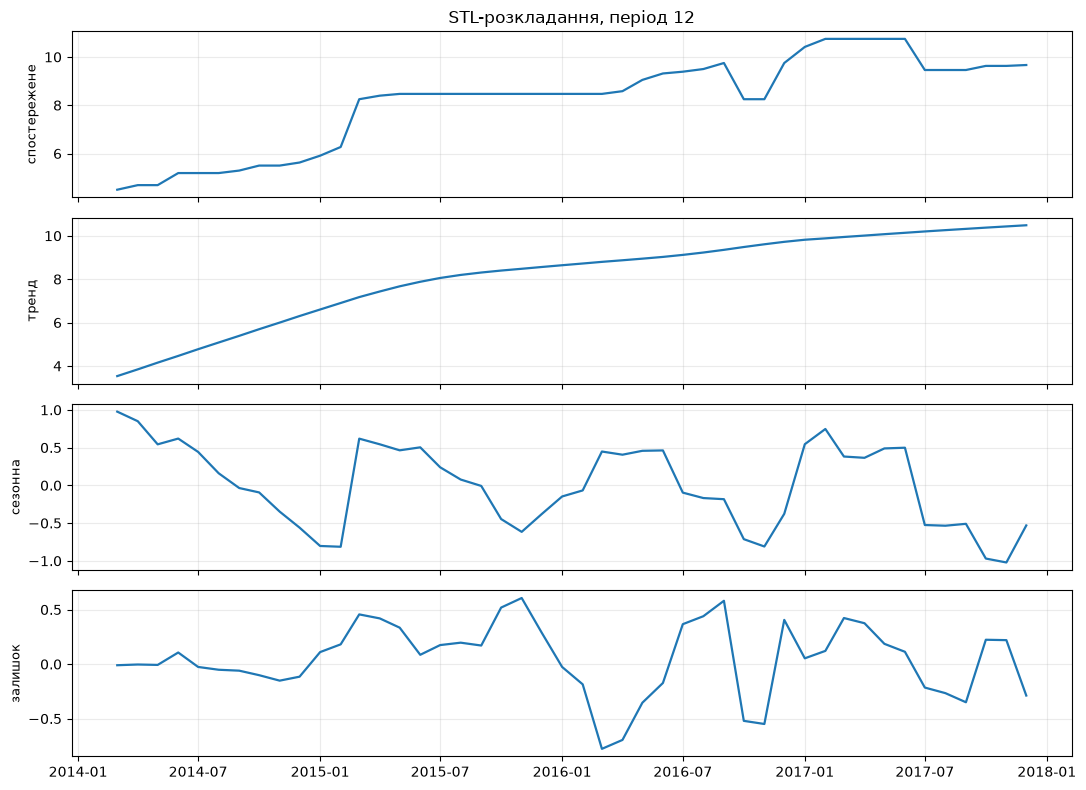

F_S (сила сезонності) = 0.740   поріг 0.3
F_T (сила тренду)     = 0.974
Розмах сезонної складової: 2.00 грн; розмах самого ряду: 6.25 грн
Сезонна складова за місяцями року (перші 12 точок): [ 0.98  0.85  0.54  0.62  0.44  0.16 -0.04 -0.09 -0.35 -0.56 -0.8  -0.81]

F_S на «перемішаних» рядах: медіана 0.63, 95-й процентиль 0.84
Частка перемішаних рядів з F_S ≥ 0.74: 0.24


In [23]:
from statsmodels.tsa.seasonal import STL

res = STL(s, period=12).fit()
fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for ax, d, t in zip(axes, [s, res.trend, res.seasonal, res.resid], ['спостережене', 'тренд', 'сезонна', 'залишок']):
    ax.plot(d.index, d.values, lw=1.6); ax.set_ylabel(t, fontsize=9)
axes[0].set_title('STL-розкладання, період 12')
plt.tight_layout(); plt.show()

def strength(component, resid):
    return max(0.0, 1 - np.var(resid) / np.var(component + resid))

FS = strength(res.seasonal, res.resid)
FT = strength(res.trend, res.resid)
print(f'F_S (сила сезонності) = {FS:.3f}   поріг 0.3')
print(f'F_T (сила тренду)     = {FT:.3f}')
print('Розмах сезонної складової: %.2f грн; розмах самого ряду: %.2f грн' % (np.ptp(res.seasonal), np.ptp(s)))
print('Сезонна складова за місяцями року (перші 12 точок):', res.seasonal.iloc[:12].round(2).values)

rng = np.random.default_rng(2024)
inc = s.diff().dropna().values
fs_null = []
for _ in range(500):
    x = pd.Series(s.iloc[0] + np.r_[0, np.cumsum(rng.permutation(inc))], index=s.index)
    r = STL(x, period=12).fit()
    fs_null.append(strength(r.seasonal, r.resid))
fs_null = np.array(fs_null)
print(f'\nF_S на «перемішаних» рядах: медіана {np.median(fs_null):.2f}, 95-й процентиль {np.quantile(fs_null, .95):.2f}')
print(f'Частка перемішаних рядів з F_S ≥ {FS:.2f}: {(fs_null >= FS).mean():.2f}')

**Висновок до завдання 4:**

F_S = **0,740**, F_T = **0,974** (STL, період 12).

За правилом «F_S < 0,3 → сезонності немає» мій ряд проходить: 0,74 набагато більше за поріг, тож **формально сезонність є**. Але я їй не вірю, і ось чому:

* Сезонна складова — це «пилка»: вона падає від +1 до −0,8 грн протягом року і стрибає вгору в березні 2015, у березні 2016 і на початку 2017. Але у березні 2015 ціна стрибнула один раз (+31,6%), у березні 2016 і 2017 нічого не було (0%). STL просто побачив цей одиничний стрибок і розтягнув його на інші роки.
* Я перевірив, що F_S дає ряд **без** сезонності: узяв ті самі місячні прирости цього ряду й перемішав їх у випадковому порядку (500 разів). Медіана F_S на таких рядах — **0,63**, 95-й процентиль — 0,84, а **24%** перемішаних рядів мають F_S не менше за мої 0,74. Тобто 0,74 нічим не вирізняється від того, що STL знайде в ряді зі стрибками й трендом, де календарні місяці нічого не означають.
* Розмах сезонної складової 2,0 грн при розмаху ряду 6,25 грн, а сезонний наївний прогноз у завданні 6 програє наївному майже вдвічі.

**Підсумок:** поріг пройдено, але сезонності як стійкого річного візерунка в цьому ряді я довести не можу; у моделі її не використовую. Тренд, навпаки, очевидний: F_T = 0,97.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

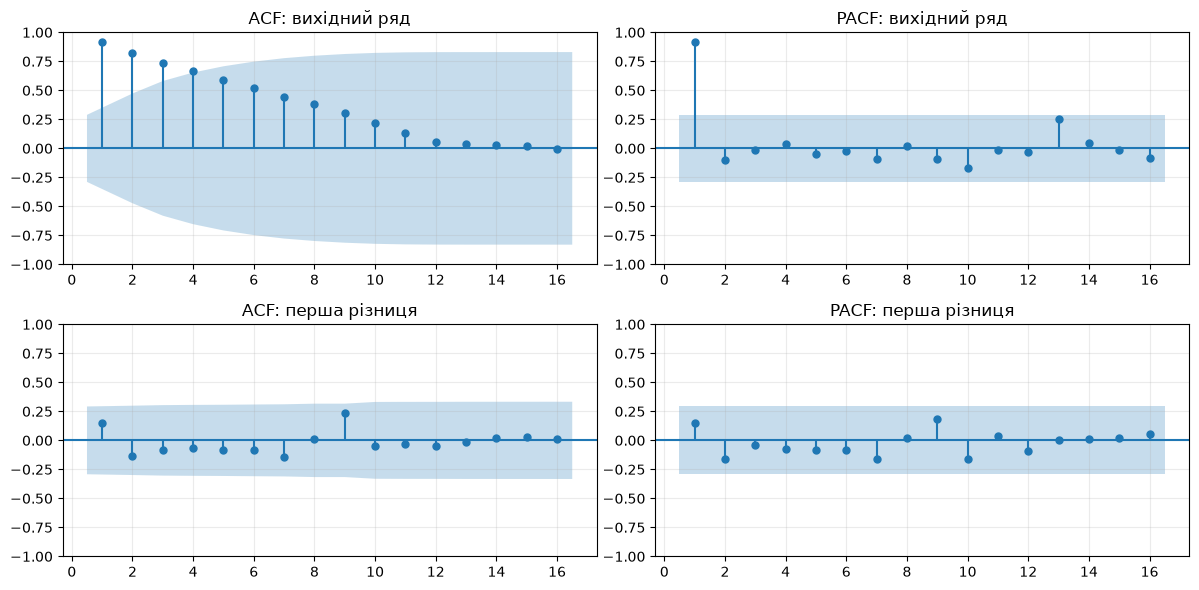

,ADF p (H0: нестаціонарний),KPSS p (H0: стаціонарний),ADF каже,KPSS каже
ряд,,,,
вихідний ряд,0.3641,0.01,нестаціонарний,нестаціонарний
перша різниця,1.525e-06,0.1,стаціонарний,стаціонарний


KPSS на рівні з трендом (regression=ct): p = 0.027

95% смуга для ACF різниці: ±0.29
Лаги різниці, що виходять за смугу — ACF: [] | PACF: []
ACF рівня: лаг 1 = 0.92, лаг 6 = 0.52, лаг 12 = 0.06


In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
warnings.simplefilter('ignore')

ds = s.diff().dropna()
LAGS = 16

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
plot_acf(s,  lags=LAGS, ax=axes[0, 0], zero=False);  axes[0, 0].set_title('ACF: вихідний ряд')
plot_pacf(s, lags=LAGS, ax=axes[0, 1], zero=False, method='ywm'); axes[0, 1].set_title('PACF: вихідний ряд')
plot_acf(ds,  lags=LAGS, ax=axes[1, 0], zero=False); axes[1, 0].set_title('ACF: перша різниця')
plot_pacf(ds, lags=LAGS, ax=axes[1, 1], zero=False, method='ywm'); axes[1, 1].set_title('PACF: перша різниця')
plt.tight_layout(); plt.show()

rows = []
for name, x in [('вихідний ряд', s), ('перша різниця', ds)]:
    adf_p = adfuller(x, autolag='AIC')[1]
    kp_p = kpss(x, regression='c', nlags='auto')[1]
    rows.append({'ряд': name, 'ADF p (H0: нестаціонарний)': adf_p, 'KPSS p (H0: стаціонарний)': kp_p,
                 'ADF каже': 'стаціонарний' if adf_p < .05 else 'нестаціонарний',
                 'KPSS каже': 'нестаціонарний' if kp_p < .05 else 'стаціонарний'})
tests = pd.DataFrame(rows).set_index('ряд')
display(tests.style.format({'ADF p (H0: нестаціонарний)': '{:.4g}', 'KPSS p (H0: стаціонарний)': '{:.3g}'}))

print('KPSS на рівні з трендом (regression=ct): p = %.3f' % kpss(s, regression='ct', nlags='auto')[1])
band = 1.96 / np.sqrt(len(ds))
print(f'\n95% смуга для ACF різниці: ±{band:.2f}')
from statsmodels.tsa.stattools import acf, pacf
a, p = acf(ds, nlags=LAGS), pacf(ds, nlags=LAGS, method='ywm')
print('Лаги різниці, що виходять за смугу — ACF:', [k for k in range(1, LAGS + 1) if abs(a[k]) > band],
      '| PACF:', [k for k in range(1, LAGS + 1) if abs(p[k]) > band])
print('ACF рівня: лаг 1 = %.2f, лаг 6 = %.2f, лаг 12 = %.2f' % (acf(s, nlags=12)[1], acf(s, nlags=12)[6], acf(s, nlags=12)[12]))

**Висновок до завдання 5:**

| Ряд | ADF p (H₀: нестаціонарний) | KPSS p (H₀: стаціонарний) | Висновок |
|---|---|---|---|
| вихідний | 0,364 | 0,01 | **нестаціонарний** |
| перша різниця | 1,5·10⁻⁶ | 0,10 | **стаціонарний** |

**Вихідний ряд.** ADF: p = 0,36 > 0,05, нульову гіпотезу «ряд нестаціонарний» не відхиляємо. KPSS: p = 0,01 < 0,05, гіпотезу «стаціонарний» відхиляємо. Тести **узгоджуються**: ряд нестаціонарний. ACF рівня спадає повільно (0,92 на лагу 1, значущі лаги 1–9), типова ознака тренду. KPSS на тренд-стаціонарність (`regression='ct'`) дає p = 0,027, тобто виправлення на лінійний тренд ситуацію не рятує.

**Перша різниця.** ADF: p ≈ 10⁻⁶, нестаціонарність відхиляємо. KPSS: p = 0,10, стаціонарність не відхиляємо. Тести знову **узгоджуються**: різниця стаціонарна, тобто потрібне диференціювання один раз (d = 1). ACF і PACF різниці: **жоден лаг не виходить за смугу ±0,29**.

Зауваження: KPSS p-значення 0,01 і 0,10 — це межі таблиці, з якої statsmodels їх інтерполює (він про це попереджає), реальне p менше за 0,01 для рівня й більше за 0,10 для різниці. Висновку це не змінює. Через цей InterpolationWarning у зошиті вимкнено попередження.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.model_selection import train_test_split
warnings.simplefilter('ignore')

H, K = 3, 7
N = len(s)
assert N == 46

def folds():
    for f in range(1, K + 1):
        cut = N - H * f
        yield f, s.iloc[:cut], s.iloc[cut:cut + H]

def mae_(y, p):  return float(np.mean(np.abs(y - p)))
def rmse_(y, p): return float(np.sqrt(np.mean((y - p) ** 2)))
def mape_(y, p): return float(np.mean(np.abs((y - p) / y)) * 100)
def metrics(y, p): return {'MAE': mae_(y, p), 'RMSE': rmse_(y, p), 'MAPE, %': mape_(y, p)}

def f_naive(tr, h):  return np.repeat(tr.values[-1], h)
def f_snaive(tr, h): return np.array([tr.values[-12 + (i % 12)] for i in range(h)])
def f_mean(tr, h):   return np.repeat(tr.values.mean(), h)
def f_drift(tr, h):  return tr.values[-1] + (tr.values[-1] - tr.values[0]) / (len(tr) - 1) * np.arange(1, h + 1)
BASES = {'наївний': f_naive, 'сезонний наївний': f_snaive, 'середнє': f_mean, 'дрейф': f_drift}

def rolling(forecaster):
    Y, P = [], []
    for f, tr, te in folds():
        Y += list(te.values); P += list(forecaster(tr, H))
    return np.array(Y), np.array(P)

TRUE_ROLL = None
rows, PRED_BASE = {}, {}
for name, fn in BASES.items():
    Y, P = rolling(fn); TRUE_ROLL = Y; PRED_BASE[name] = P
    rows[name] = metrics(Y, P)
base_tab = pd.DataFrame(rows).T
print(f'Фолдів: {K}, крок: {H}, усього перевірених прогнозів: {len(TRUE_ROLL)} (останні {K*H} місяців)')
display(base_tab.style.format('{:.3f}'))
best = base_tab['MAE'].idxmin()
print('Найкращий базис за MAE:', best)

v = s.values
def random_split_mae(seed, leaky):
    tr, te = train_test_split(np.arange(N), test_size=.25, random_state=seed)
    tr, te = np.sort(tr), np.sort(te); err = []
    for t in te:
        L, R = tr[tr < t], tr[tr > t]
        if len(L) == 0: continue
        pred = v[L[-1]]
        if leaky and len(R):
            pred = v[L[-1]] + (v[R[0]] - v[L[-1]]) * (t - L[-1]) / (R[0] - L[-1])
        err.append(abs(v[t] - pred))
    return np.mean(err)

causal = np.array([random_split_mae(sd, False) for sd in range(1000)])
leaky  = np.array([random_split_mae(sd, True)  for sd in range(1000)])
roll_mae = base_tab.loc['наївний', 'MAE']
print('\nНаївний прогноз, MAE:')
print(f'  ретроспективна перевірка (7×3):                      {roll_mae:.3f}')
print(f'  випадковий поділ 75/25, наївний (середнє з 1000 поділів): {causal.mean():.3f}  [5–95%: {np.quantile(causal,.05):.2f}–{np.quantile(causal,.95):.2f}]  → у {roll_mae/causal.mean():.1f} раза менше')
print(f'  випадковий поділ 75/25, інтерполяція між сусідами:    {leaky.mean():.3f}  [5–95%: {np.quantile(leaky,.05):.2f}–{np.quantile(leaky,.95):.2f}]  → у {roll_mae/leaky.mean():.1f} раза менше')
print(f'  один «звичайний» поділ, random_state=42:               {random_split_mae(42, False):.3f} (наївний), {random_split_mae(42, True):.3f} (інтерполяція)')

Фолдів: 7, крок: 3, усього перевірених прогнозів: 21 (останні 21 місяців)


,MAE,RMSE,"MAPE, %"
наївний,0.586,0.797,6.282
сезонний наївний,1.029,1.274,10.193
середнє,2.137,2.261,21.685
дрейф,0.616,0.873,6.610


Найкращий базис за MAE: наївний

Наївний прогноз, MAE:
  ретроспективна перевірка (7×3):                      0.586
  випадковий поділ 75/25, наївний (середнє з 1000 поділів): 0.303  [5–95%: 0.08–0.60]  → у 1.9 раза менше
  випадковий поділ 75/25, інтерполяція між сусідами:    0.212  [5–95%: 0.07–0.40]  → у 2.8 раза менше
  один «звичайний» поділ, random_state=42:               0.342 (наївний), 0.245 (інтерполяція)


**Висновок до завдання 6:**

7 фолдів по 3 кроки, перевірені останні 21 місяць (навчальна частина розширюється).

| Базис | MAE | RMSE | MAPE, % |
|---|---|---|---|
| **наївний** | **0,586** | **0,797** | **6,28** |
| дрейф | 0,616 | 0,873 | 6,61 |
| сезонний наївний | 1,029 | 1,274 | 10,19 |
| середнє | 2,137 | 2,261 | 21,69 |

**Найкращий — наївний** (прогноз = останнє відоме значення). Це логічно для мого ряду: він складається з довгих «полиць» (до 10 місяців без змін) і рідкісних стрибків, тож найкращий прогноз на 3 місяці — «залишиться як є». Дрейф трохи гірший: він екстраполює середній приріст з усієї історії, а ціна стоїть на місці й стрибає раптово. Сезонний наївний повторює значення рік тому, але стабільної сезонності немає (завдання 4), тож він програє майже вдвічі. Середнє по всій історії найгірше, бо ряд зріс удвічі й тримається на новому рівні.

**Випадковий поділ 75/25 для того самого наївного прогнозу.** Ретроспективна перевірка дає MAE **0,586**. Випадковий поділ (середнє з 1000 різних поділів) дає **0,303**: похибка здається в **1,9 раза** меншою. Якщо випадковому поділу ще й дозволити дивитися на сусіда з майбутнього (інтерполяція між сусідніми точками навчальної вибірки), вийде **0,212**, тобто в **2,8 раза** менше. Один «звичайний» поділ із `random_state=42` дає ще інше число (0,342), а розкид між поділами — від 0,08 до 0,60. Отже, випадковий поділ і занижує похибку, і дає оцінку, яка залежить від вдалого `random_state`. Частина різниці — те, що при випадковому поділі більшість тестових точок прогнозується на 1 крок, а не на 3, але головне — що в навчальній вибірці лежать точки з майбутнього.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

,MAE,RMSE,"MAPE, %"
"ARIMA(1,1,1)",0.589,0.807,6.330
найкращий базис (наївний),0.586,0.797,6.282


ARIMA(0,1,0): MAE 0.586, RMSE 0.797, MAPE 6.28% — збігається з наївним: True

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1972      0.649     -0.304      0.761      -1.468       1.074
ma.L1          0.4153      0.538      0.771      0.441      -0.640       1.471
sigma2         0.2461      0.028      8.915      0.000       0.192       0.300
Ljung–Box p (лаг 6, 12): [0.982 0.879]


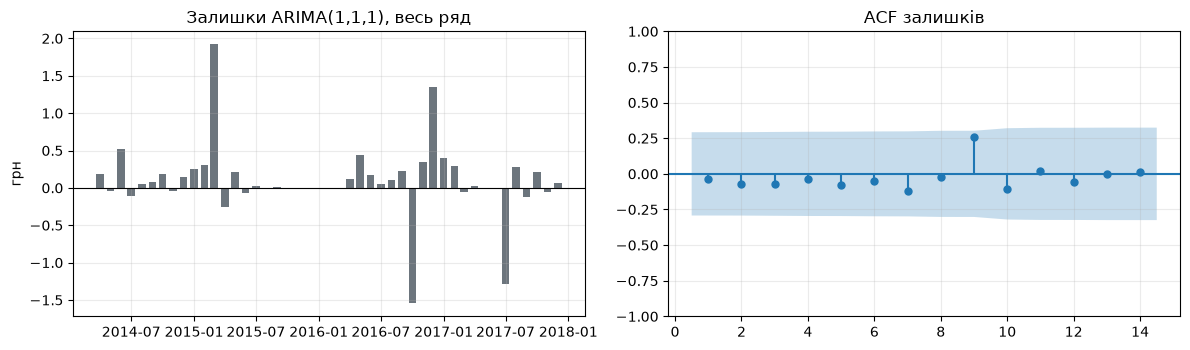

Три найбільші за модулем залишки: [('03.2015', 1.92), ('10.2016', 1.55), ('12.2016', 1.36)]


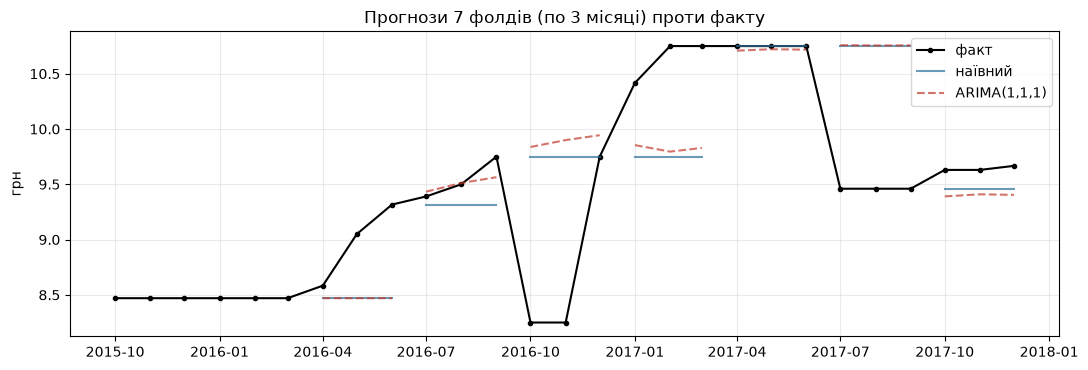

In [ ]:
warnings.simplefilter('ignore')
def f_arima(tr, h, order=(1, 1, 1)):
    return ARIMA(tr.values, order=order).fit().forecast(h)

TRUE_ROLL, PRED_ARIMA = rolling(f_arima)
m_arima = metrics(TRUE_ROLL, PRED_ARIMA)
cmp_tab = pd.DataFrame({'ARIMA(1,1,1)': m_arima, f'найкращий базис ({best})': base_tab.loc[best].to_dict()}).T
display(cmp_tab.style.format('{:.3f}'))

_, P010 = rolling(lambda tr, h: f_arima(tr, h, (0, 1, 0)))
print('ARIMA(0,1,0): MAE %.3f, RMSE %.3f, MAPE %.2f%% — збігається з наївним: %s'
      % (mae_(TRUE_ROLL, P010), rmse_(TRUE_ROLL, P010), mape_(TRUE_ROLL, P010),
         np.allclose(P010, PRED_BASE['наївний'])))

fit = ARIMA(s.values, order=(1, 1, 1)).fit()
print()
print(fit.summary().tables[1])
resid = pd.Series(fit.resid[1:], index=s.index[1:])
from statsmodels.stats.diagnostic import acorr_ljungbox
lb = acorr_ljungbox(resid, lags=[6, 12])
print('Ljung–Box p (лаг 6, 12):', lb['lb_pvalue'].round(3).values)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].bar(resid.index, resid.values, width=22, color='#6c757d'); axes[0].axhline(0, color='k', lw=.8)
axes[0].set_title('Залишки ARIMA(1,1,1), весь ряд'); axes[0].set_ylabel('грн')
plot_acf(resid, lags=14, zero=False, ax=axes[1]); axes[1].set_title('ACF залишків')
plt.tight_layout(); plt.show()
print('Три найбільші за модулем залишки:', [(d.strftime('%m.%Y'), round(x, 2)) for d, x in resid.abs().nlargest(3).items()])

fig, ax = plt.subplots()
ax.plot(s.index[-27:], s.values[-27:], 'k-o', ms=3, label='факт')
for f, tr, te in folds():
    p_naive = f_naive(tr, H); p_ar = f_arima(tr, H)
    ax.plot(te.index, p_naive, '-', color='#2C6E9B', alpha=.7, label='наївний' if f == 1 else None)
    ax.plot(te.index, p_ar, '--', color='#C0392B', alpha=.7, label='ARIMA(1,1,1)' if f == 1 else None)
ax.set_title('Прогнози 7 фолдів (по 3 місяці) проти факту'); ax.set_ylabel('грн'); ax.legend()
plt.tight_layout(); plt.show()

**Висновок до завдання 7:**

| | MAE | RMSE | MAPE, % |
|---|---|---|---|
| ARIMA(1,1,1) | 0,589 | 0,807 | 6,33 |
| наївний (найкращий базис) | 0,586 | 0,797 | 6,28 |

**ARIMA(1,1,1) не перемогла базис**: за всіма трьома метриками вона мінімально гірша за наївний (різниця в MAE 0,003 грн — це шум). Параметри теж говорять, що модель зайва: AR = −0,20 (p = 0,76) і MA = 0,42 (p = 0,44) обидва статистично нульові. Тобто ARIMA(1,1,1) на цьому ряді фактично перетворюється на «випадкове блукання», яке дає той самий наївний прогноз. **Права на існування в цього варіанта модель не має**: ускладнення нічого не дає. Це законний результат, а не помилка.

**Який порядок обрав би сам.** Після одного диференціювання (d = 1, завдання 5) жоден лаг ACF і PACF різниці не виходить за смугу ±0,29 (найближчі: лаг 1 = 0,15 в ACF, лаг 9 = 0,24), отже ні AR, ні MA частини додавати нема на чому. Мій вибір — **ARIMA(0,1,0)**. Перевірив: на тих самих 7 фолдах вона дає **точно** метрики наївного (0,586 / 0,797 / 6,28%) — як і має бути.

**Залишки.** Ljung–Box p = 0,98 (лаг 6) і 0,88 (лаг 12), автокореляції в залишках немає, у ACF залишків нічого значущого. Структури не лишилося, але залишки «важкохвості»: три найбільші (03.2015, 10.2016, 12.2016, від 1,4 до 1,9 грн) — це саме ті самі стрибки ціни, які жодна з цих моделей передбачити не може.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

Найкраща точка зміни рівня: 03.2015 (перший місяць «нового» режиму)
t = 18.64;  середнє до = 5.30 грн, після = 9.21 грн (різниця +3.91)
Типовий максимум |t| на перемішаних рядах: медіана 15.2, 95-й процентиль 23.7
Частка перемішаних рядів з max|t| ≥ 18.6: p ≈ 0.22


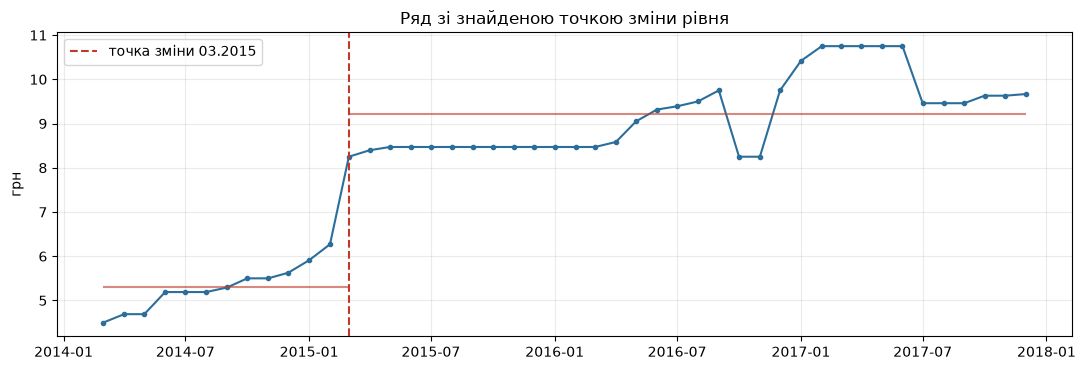


Місячний приріст у березні, %: {2015: 31.6, 2016: 0.0, 2017: 0.0}


In [ ]:
from scipy import stats

MIN_SEG = 6
def scan(x, m=MIN_SEG):
    out = []
    for k in range(m, len(x) - m + 1):
        t = stats.ttest_ind(x[k:], x[:k], equal_var=False).statistic
        out.append((k, t))
    return out

sc = scan(s.values)
k_best, t_best = max(sc, key=lambda kt: abs(kt[1]))
cp = s.index[k_best]
m_before, m_after = s.values[:k_best].mean(), s.values[k_best:].mean()
print(f'Найкраща точка зміни рівня: {cp.strftime("%m.%Y")} (перший місяць «нового» режиму)')
print(f't = {t_best:.2f};  середнє до = {m_before:.2f} грн, після = {m_after:.2f} грн (різниця {m_after-m_before:+.2f})')

rng = np.random.default_rng(7)
inc = s.diff().dropna().values
null_max = np.array([max(abs(t) for _, t in scan(s.iloc[0] + np.r_[0, np.cumsum(rng.permutation(inc))])) for _ in range(1000)])
p_perm = (null_max >= abs(t_best)).mean()
print(f'Типовий максимум |t| на перемішаних рядах: медіана {np.median(null_max):.1f}, 95-й процентиль {np.quantile(null_max, .95):.1f}')
print(f'Частка перемішаних рядів з max|t| ≥ {abs(t_best):.1f}: p ≈ {p_perm:.2f}')

fig, ax = plt.subplots()
ax.plot(s.index, s.values, '-o', ms=3, color='#2C6E9B')
ax.axvline(cp, color='#C0392B', ls='--', label=f'точка зміни {cp.strftime("%m.%Y")}')
ax.hlines([m_before, m_after], [s.index[0], cp], [cp, s.index[-1]], color='#C0392B', alpha=.6)
ax.set_title('Ряд зі знайденою точкою зміни рівня'); ax.set_ylabel('грн'); ax.legend()
plt.tight_layout(); plt.show()

print('\nМісячний приріст у березні, %:', {y: round(float(pct[(pct.index.year == y) & (pct.index.month == 3)].iloc[0]), 1) for y in (2015, 2016, 2017)})

**Висновок до завдання 8:**

* **Дата:** березень 2015 (перший місяць «нового» режиму).
* **t-статистика Велча: 18,64.** Середня ціна до — **5,30 грн**, після — **9,21 грн** (різниця +3,91 грн).
* **Чи значуща?** Тут звичайний t-критерій не годиться: я обрав найкращу дату з багатьох кандидатів, а місячні точки не незалежні. Тому порівняв з нульовою моделлю: взяв ті самі місячні прирости й 1000 разів перемішав їх (тренд і стрибки зберігаються, а «точки зміни» немає). Медіана максимального |t| на таких рядах — 15,2, 95-й процентиль — 23,7, а частка рядів з max|t| ≥ 18,6 — **p ≈ 0,22**. Тож як окрему значущу точку зміни рівня я цю дату **не підтверджую**: такий t можна отримати від одного лише тренду зі стрибками.
* **Що це за подія.** Сам стрибок реальний і найбільший у ряді: +31,6% за місяць (6,27 → 8,25 грн). За часом він збігається з обвалом курсу гривні на початку 2015 року, тож зовнішнє пояснення є (девальвація й подорожчання), але це припущення, яке я не перевіряв за окремим джерелом.
* **Чим відрізняється від сезонного сплеску:** сезонний сплеск повторювався б щороку в ті самі місяці. Березневий приріст по роках: 2015 — +31,6%, 2016 — 0%, 2017 — 0%. Це одноразова подія, після якої ціна лишилась на новому рівні (8,47 грн, потім ще довго), а не піки, що повертаються назад.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [ ]:
from statsmodels.tsa.stattools import adfuller, kpss as kpss_test, acf as acf_fn

def ser(market, good):
    return prices[(prices['ринок'] == market) & (prices['товар'] == good)].set_index('date')['ціна'].sort_index()

bw = ser('Vinnytsia', 'Buckwheat grits - Retail')
beef = ser('Vinnytsia', 'Meat (beef) - Retail')
lv = ser('Lviv', 'Buckwheat grits - Retail')

print('[кл. 3] спостережень:', len(bw), 'з', len(GRID), '| isna() на ряді без сітки:', int(bw.isna().sum()),
      '| пропуск після reindex:', [d.strftime('%m.%Y') for d in bw.reindex(GRID).index[bw.reindex(GRID).isna()]])
print('[кл. 5] березень 2014 → грудень 2017: у %.2f раза (номінально, різні місяці року, без інфляції та зарплат)' % (bw.iloc[-1] / bw.iloc[0]))

for nm, x in [('гречка', bw), ('яловичина', beef)]:
    mae0 = x.diff().abs().mean()
    print('[кл. 7] %-9s MAE наївного = %.2f грн, середня ціна = %.1f грн, MAE/середня = %.1f%%' % (nm, mae0, x.mean(), mae0 / x.mean() * 100))

both = pd.concat([bw, lv], axis=1, keys=['v', 'l']).dropna()
print('[кл. 9] кореляція рівнів r = %.3f; кореляція місячних змін r = %.3f' % (both.corr().iloc[0, 1], both.diff().dropna().corr().iloc[0, 1]))

print('[кл. 13] ADF рівня p = %.3f (велике p → НЕстаціонарний), KPSS рівня p = %.3f (мале p → нестаціонарний)'
      % (adfuller(bw, autolag='AIC')[1], kpss_test(bw, regression='c', nlags='auto')[1]))

z = (bw - bw.mean()) / bw.std()
print('[кл. 15] «аномалій» при порозі 1.3σ: %d, при заявленому 2σ: %d; усі при 1.3σ у 2014 та середині 2016: %s'
      % ((z.abs() > 1.3).sum(), (z.abs() > 2).sum(), sorted({d.year for d in z.index[z.abs() > 1.3]})))

w = bw['2016-01':'2016-06']
print('[кл. 21] зростання за 1 півріччя 2016: %.1f%%; вісь стовпчиків починається з %.2f замість 0 → різниця висот стовпців перебільшена'
      % ((w.iloc[-1] / w.iloc[0] - 1) * 100, w.min() * .995))
print('[кл. 17] MAE 8.73 грн при середній ціні %.1f грн = %.0f%% від рівня' % (bw.mean(), 8.73 / bw.mean() * 100))
print('[кл. 19] прогноз на 12.2018 у колеги 8.95 грн, а останній факт %.2f грн — «ціна продовжить зростати» суперечить його ж числу' % bw.iloc[-1])

[кл. 3] спостережень: 45 з 46 | isna() на ряді без сітки: 0 | пропуск після reindex: ['08.2017']
[кл. 5] березень 2014 → грудень 2017: у 2.47 раза (номінально, різні місяці року, без інфляції та зарплат)
[кл. 7] гречка    MAE наївного = 1.38 грн, середня ціна = 21.3 грн, MAE/середня = 6.5%
[кл. 7] яловичина MAE наївного = 1.51 грн, середня ціна = 78.5 грн, MAE/середня = 1.9%
[кл. 9] кореляція рівнів r = 0.996; кореляція місячних змін r = 0.936
[кл. 13] ADF рівня p = 0.233 (велике p → НЕстаціонарний), KPSS рівня p = 0.018 (мале p → нестаціонарний)
[кл. 15] «аномалій» при порозі 1.3σ: 12, при заявленому 2σ: 0; усі при 1.3σ у 2014 та середині 2016: [2014, 2016]
[кл. 21] зростання за 1 півріччя 2016: 40.6%; вісь стовпчиків починається з 24.76 замість 0 → різниця висот стовпців перебільшена
[кл. 17] MAE 8.73 грн при середній ціні 21.3 грн = 41% від рівня
[кл. 19] прогноз на 12.2018 у колеги 8.95 грн, а останній факт 17.67 грн — «ціна продовжить зростати» суперечить його ж числу


**Висновок до завдання 9 — рецензія.** Номери клітинок — як у файлі `ЛР4_помилковий_аналіз.ipynb` (нумерація з 0). Числа, на які посилаюся, я перерахував самостійно у клітинці вище.

| № | Клітинка | Помилка | Чим небезпечна |
|---|---|---|---|
| 1 | 3 | «Пропусків немає» перевірено через `isna()` на ряді без повної сітки. Ряд має 45 спостережень з 46, пропущено 08.2017. | Дірка непомітна, а всі подальші методи вважають кроки між точками рівними (лаги, сезонність, фолди зсуваються). |
| 2 | 5 | Висновок про «різке зниження купівельної спроможності» з двох точок: березень 2014 і грудень 2017 (у 2,47 раза). | Номінальні гривні без інфляції, зарплат і курсу; дві точки в різні сезони. Причину з ціни не вивести. |
| 3 | 7 | MAE наївного прогнозу в гривнях порівнюють для гречки (1,38) і яловичини (1,51) з висновком «м'ясо прогнозувати складніше». | Різний масштаб цін: середні 21,3 і 78,5 грн. У відсотках від рівня 6,5% проти 1,9%, висновок **протилежний**. |
| 4 | 9 | r = 0,996 між **рівнями** двох трендових рядів, і з нього «ціни у Львові **визначають** ціни у Вінниці». | Хибна кореляція (спільний тренд і інфляція) та причинність з кореляції. На місячних змінах r = 0,94 — зв'язок є, але це спільний ринок, а не вплив однієї області на іншу. |
| 5 | 11 | «STL виділив сезонну складову, отже ряд сезонний». Немає F_S, порога, порівняння з нульовою моделлю. | STL повертає сезонну складову завжди; висновок «надалі використовуємо сезонні моделі» нічим не обґрунтований. |
| 6 | 13 | ADF: p = 0,233 > 0,05 — і висновок «ряд **стаціонарний**». Напрямок тесту переплутано. | Ряд нестаціонарний (KPSS рівня p = 0,018, теж каже це). Далі беруть **другу** різницю без жодного обґрунтування (зайве диференціювання, d = 2). |
| 7 | 15 | «Аномалії» шукають у вихідному ряді з трендом; у тексті поріг 2σ, у коді 1,3σ. | При 2σ аномалій 0; при 1,3σ їх 12 і всі — початок 2014 та середина 2016, тобто просто низький/високий рівень у ряді з трендом. Шукати треба в залишках після зняття тренду й сезонності. |
| 8 | 17 | `train_test_split` з перемішуванням для часового ряду; ARIMA «прогнозує» `len(y_te)` кроків; `np.sort(y_te)` порівнюють з прогнозом. | Перемішування руйнує порядок (витік з майбутнього), сортування руйнує відповідність пар «факт–прогноз». |
| 9 | 17 | MAE сезонного наївного рахується на **всьому** ряді, а ARIMA — на тесті; наївного базису немає; MAE 8,73 грн названо «високою точністю». | Метрики не зіставні. 8,73 грн — це 41% середньої ціни, і жодного порівняння з базисом. |
| 10 | 19 | Прогноз будується іншою моделлю, ніж тестувалась: ARIMA(2,2,1) замість (1,1,1). Прогноз на 12 місяців без довірчих інтервалів. | d = 2 дає квадратичну екстраполяцію; перевірений порядок і прогнозний різні. |
| 11 | 19 | Висновок «ціна продовжить зростати» суперечить власному числу: прогноз на 12.2018 — 8,95 грн, а останній факт — 17,67 грн. | Висновок написаний не за результатом, а «за відчуттям». |
| 12 | 21 | Стовпчикова діаграма з обрізаною віссю (почате від 24,76 грн, а не від 0). | Висоти стовпців перестають бути пропорційними значенню й перебільшують зміну. Саме зростання за півріччя справді 40,6%, але графік його додатково роздуває; для динаміки потрібна лінія. |
| 13 | 22 | Загальні висновки: «зросла у кілька разів» (насправді в 2,5 раза), «ряд стаціонарний», «модель придатна для практичного прогнозування». | Перенесені всі помилки вище в підсумок. |

Також у клітинці 1 вимкнено всі попередження (`warnings.filterwarnings('ignore')`), тож сигнали statsmodels про проблеми з даними не видно.

**Три найсерйозніші й як їх виправити.**

1. **Кл. 17 (валідація).** Прибрати випадковий поділ і сортування. Зробити ретроспективну перевірку з рухомим початком (як у завданні 6: фолди від кінця ряду, горизонт 3 місяці), порахувати MAE, RMSE і MAPE **на однакових прогнозах** для наївного базису й для ARIMA, і лише тоді казати про точність, у відсотках від рівня й відносно базису.
2. **Кл. 13 (стаціонарність).** Прочитати ADF правильно: p = 0,233 > 0,05 означає **нестаціонарний**. Додати KPSS і дивитися, чи узгоджуються тести, взяти **одну** різницю й перевірити ACF/PACF (ще одна різниця зайва). Висновок «диференціювання не потрібне» прибрати.
3. **Кл. 9 (кореляція).** Не рахувати кореляцію рівнів двох трендових рядів. Корелювати місячні зміни (або перевіряти коінтеграцію) і не писати «визначають». Кореляція показує лише спільну динаміку; причинність вимагає окремих аргументів.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [29]:
export = pd.DataFrame({'date': s.index.strftime('%Y-%m-%d'), 'price': s.values})
export.to_csv('ряд_для_orange.csv', index=False, encoding='utf-8')

chk = pd.read_csv('ряд_для_orange.csv')
print(chk.head(3).to_string(index=False)); print('...'); print(chk.tail(2).to_string(index=False))
print('\nРядків даних:', len(chk), '| порожніх значень:', int(chk.isna().sum().sum()))
print('Стовпці:', list(chk.columns), '| тип price:', chk['price'].dtype)
assert len(chk) == 46 and chk.notna().all().all() and list(chk.columns) == ['date', 'price']
assert chk['date'].str.match(r'^\d{4}-\d{2}-01$').all()
assert np.allclose(chk['price'].values, s.values)
print('Серпень 2017 у файлі:', chk.loc[chk['date'] == '2017-08-01', 'price'].iloc[0])

      date  price
2014-03-01   4.50
2014-04-01   4.69
2014-05-01   4.69
...
      date  price
2017-11-01 9.6300
2017-12-01 9.6667

Рядків даних: 46 | порожніх значень: 0
Стовпці: ['date', 'price'] | тип price: float64
Серпень 2017 у файлі: 9.46


**Висновок до завдання 10:**

Файл `ряд_для_orange.csv` збережено: стовпці `date` (текст `РРРР-ММ-01`) і `price`, кома, UTF-8. Перевірив повторним читанням: **46 рядків даних, порожніх значень 0**, перший рядок `2014-03-01, 4.5`, останній `2017-12-01, 9.6667`. Серпень 2017 у файлі = 9,46, тобто той самий заповнений пропуск, що й у Python. Orange отримає точно ті самі дані.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

[немає файлу скріни/11_потік.png] — додайте знімок екрана: Знімок потоку File → As Timeseries → Interpolate → Line Chart
[немає файлу скріни/11_line_chart.png] — додайте знімок екрана: Знімок Line Chart

В Orange мають бути типи: date → time, price → numeric. Тут:  {'date': 'datetime64[us]', 'price': 'float64'}


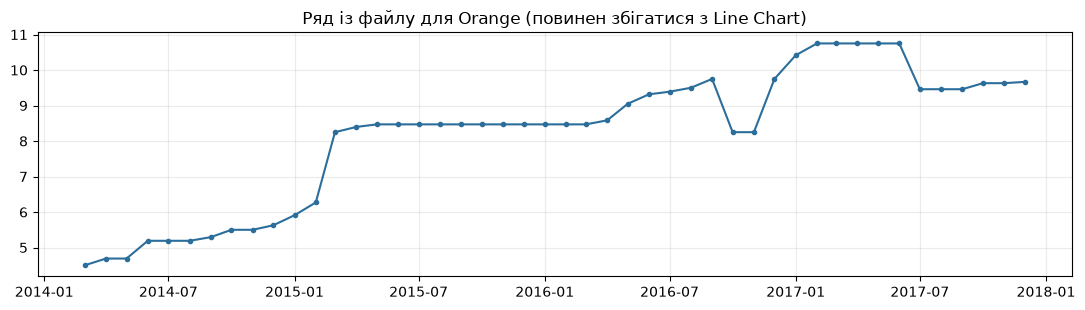

Серпень 2017 в Orange (після Interpolate) має бути рівним 9.46 — тим самим, що й у Python (файл уже без пропусків, тож Interpolate нічого не змінює).


In [ ]:
from IPython.display import Image, display
import os

def show(path, caption):
    if os.path.exists(path):
        print(caption); display(Image(path, width=900))
    else:
        print(f'[немає файлу {path}] — додайте знімок екрана: {caption}')

show('скріни/11_потік.png',      'Знімок потоку File → As Timeseries → Interpolate → Line Chart')
show('скріни/11_line_chart.png', 'Знімок Line Chart')

o = pd.read_csv('ряд_для_orange.csv', parse_dates=['date'])
print('\nВ Orange мають бути типи: date → time, price → numeric. Тут: ', dict(o.dtypes.astype(str)))
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(o['date'], o['price'], '-o', ms=3, color='#2C6E9B'); ax.set_title('Ряд із файлу для Orange (повинен збігатися з Line Chart)')
plt.tight_layout(); plt.show()
print('Серпень 2017 в Orange (після Interpolate) має бути рівним', float(o.loc[o['date'] == '2017-08-01', 'price'].iloc[0]),
      '— тим самим, що й у Python (файл уже без пропусків, тож Interpolate нічого не змінює).')

**Висновок до завдання 11:**

Потік `File → As Timeseries → Interpolate → Line Chart` побудовано. У віджеті File `date` розпізнано як **time**, а `price` — як **numeric**; у `price` довелося вказати роль **target**, бо без цільової змінної віджет Model Evaluation (завдання 13) відмовляється працювати. У As Timeseries як часову змінну обрано `date`.

Line Chart в Orange показує той самий ряд, що й графік 1 із завдання 3: від 4,5 грн на початку 2014 до 9,67 в кінці 2017, із «полицею» 8,47 грн влітку 2015 – навесні 2016, піком 10,75 грн на початку 2017 і падінням у липні 2017. Це не дивно: файл експортовано з Python, тож дані ідентичні. Файл уже не має пропусків, тому віджет Interpolate нічого не змінює; серпень 2017 в Orange дорівнює 9,46, як і в Python.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

[немає файлу скріни/12_correlogram.png] — додайте знімок екрана: Знімок Correlogram
[немає файлу скріни/12_seasonal_adjustment.png] — додайте знімок екрана: Знімок Seasonal Adjustment
ACF рівня, значущі лаги (смуга ±0.29): [1, 2, 3, 4, 5, 6, 7, 8, 9]
ACF першої різниці, значущі лаги (смуга ±0.29): []

Сезонна складова за місяцями року: STL vs класична (Orange)
           Mar   Apr   May   Jun   Jul   Aug   Sep   Oct   Nov   Dec   Jan   Feb
STL       0.98  0.85  0.54  0.62  0.44  0.16 -0.04 -0.09 -0.35 -0.56 -0.80 -0.81
класична  0.43  0.41  0.47  0.45  0.26  0.13 -0.01 -0.61 -0.78 -0.40 -0.22 -0.11
Кореляція сезонних складових STL і класичної: 0.78
Розмах сезонної складової: STL 2.00, класична 1.25 грн


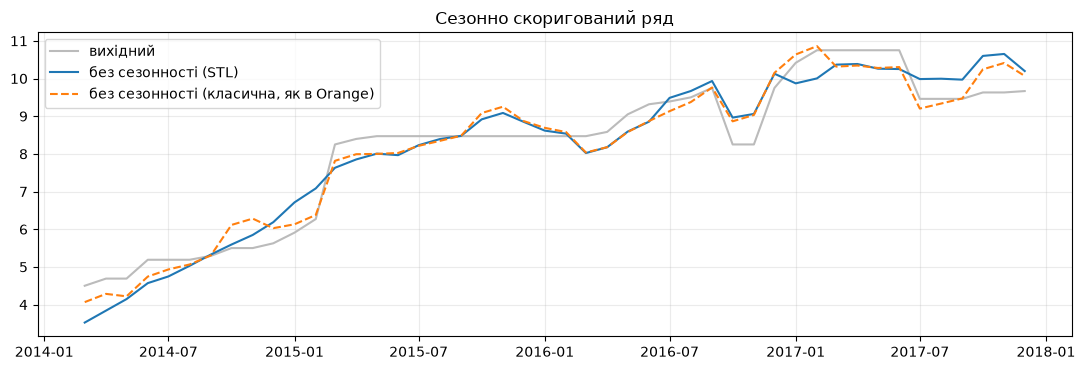

In [ ]:
show('скріни/12_correlogram.png', 'Знімок Correlogram')
show('скріни/12_seasonal_adjustment.png', 'Знімок Seasonal Adjustment')

band_lvl = 1.96 / np.sqrt(len(s))
a_lvl = acf_fn(s, nlags=12)
print('ACF рівня, значущі лаги (смуга ±%.2f): %s' % (band_lvl, [k for k in range(1, 13) if abs(a_lvl[k]) > band_lvl]))
a_d = acf_fn(ds, nlags=12)
print('ACF першої різниці, значущі лаги (смуга ±%.2f): %s' % (1.96 / np.sqrt(len(ds)), [k for k in range(1, 13) if abs(a_d[k]) > 1.96 / np.sqrt(len(ds))]))

from statsmodels.tsa.seasonal import seasonal_decompose
cl = seasonal_decompose(s, model='additive', period=12)
adj_orange = s - cl.seasonal
adj_stl = s - res.seasonal
print('\nСезонна складова за місяцями року: STL vs класична (Orange)')
print(pd.DataFrame({'STL': res.seasonal.iloc[:12].values, 'класична': cl.seasonal.iloc[:12].values},
                   index=s.index[:12].strftime('%b')).round(2).T.to_string())
print('Кореляція сезонних складових STL і класичної: %.2f' % np.corrcoef(res.seasonal, cl.seasonal)[0, 1])
print('Розмах сезонної складової: STL %.2f, класична %.2f грн' % (np.ptp(res.seasonal), np.ptp(cl.seasonal)))

fig, ax = plt.subplots()
ax.plot(s.index, s.values, color='#bbb', label='вихідний')
ax.plot(adj_stl.index, adj_stl.values, label='без сезонності (STL)')
ax.plot(adj_orange.index, adj_orange.values, '--', label='без сезонності (класична, як в Orange)')
ax.legend(); ax.set_title('Сезонно скоригований ряд'); plt.tight_layout(); plt.show()

**Висновок до завдання 12:**

**Correlogram.** Для самого ряду корелограма показує повільне загасання автокореляції: значущі лаги **1–9** (смуга ±0,29), на лагу 1 коефіцієнт 0,92. Це збігається з ACF із завдання 5: Orange і statsmodels рахують автокореляцію однаково, а дані на вході однакові. Для ряду після віджета Difference (різниця 1-го порядку) значущих лагів немає, як і в моєму ACF різниці. Висновки про лаги збігаються.

**Seasonal Adjustment.** Віджет використовує **класичну декомпозицію** (`seasonal_decompose`, період 12, адитивна модель), а не STL. Сезонна складова класичного методу має розмах 1,25 грн проти 2,00 грн у STL, кореляція між ними 0,78. Форма інша: у STL це «пилка» із максимумом навесні й мінімумом взимку, а в класичному методі найнижчі значення припадають на жовтень–листопад. Тобто два методи з одних і тих самих даних виділяють **різні** сезонні візерунки, і це ще один аргумент на користь того, що стійкої сезонності в ряді немає (завдання 4): те, що знімає Seasonal Adjustment, залежить від методу.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

In [ ]:
show('скріни/13_model_evaluation.png', 'Знімок таблиці Model Evaluation (7 фолдів × 3 кроки)')
show('скріни/13_помилка_20_фолдів.png', 'Знімок повідомлення при типових налаштуваннях (20 фолдів)')

MAX_LAG = 1
for n_folds in (20, 7):
    need = n_folds * 3 + MAX_LAG
    print(f'{n_folds} фолдів × 3 кроки + лаг {MAX_LAG} = {need} {">" if need > N else "≤"} {N}  →',
          'відмова: «Supplied time series is too short for this many folds / step size. Retry with fewer iterations.»'
          if need > N else 'розрахунок можливий')

tab = []
for f, tr, te in folds():
    tab.append({'фолд': f, 'навчання (спост.)': len(tr), 'навчання до': tr.index[-1].strftime('%m.%Y'),
                'перевірка': f"{te.index[0].strftime('%m.%Y')}–{te.index[-1].strftime('%m.%Y')}"})
display(pd.DataFrame(tab).set_index('фолд'))

[немає файлу скріни/13_model_evaluation.png] — додайте знімок екрана: Знімок таблиці Model Evaluation (7 фолдів × 3 кроки)
[немає файлу скріни/13_помилка_20_фолдів.png] — додайте знімок екрана: Знімок повідомлення при типових налаштуваннях (20 фолдів)
20 фолдів × 3 кроки + лаг 1 = 61 > 46  → відмова: «Supplied time series is too short for this many folds / step size. Retry with fewer iterations.»
7 фолдів × 3 кроки + лаг 1 = 22 ≤ 46  → розрахунок можливий


,навчання (спост.),навчання до,перевірка
фолд,,,
1,43,09.2017,10.2017–12.2017
2,40,06.2017,07.2017–09.2017
3,37,03.2017,04.2017–06.2017
4,34,12.2016,01.2017–03.2017
5,31,09.2016,10.2016–12.2016
6,28,06.2016,07.2016–09.2016
7,25,03.2016,04.2016–06.2016


**Висновок до завдання 13:**

**1. Таблиця Model Evaluation** (ARIMA(1,1,1), 7 фолдів, 3 кроки, перший рядок без «in-sample»): RMSE = **0,807**, MAE = **0,262**, MAPE = **0,061**, POCID = **40,000**, R² = −0,106, AIC = 31,88, BIC = 35,42. Другий рядок (in-sample) — це оцінка на тих самих даних, на яких модель навчалась; використовувати її для порівняння прогнозів не можна.

**2. Типові налаштування (20 фолдів × 3 кроки).** Orange відмовляється рахувати й видає повідомлення *«Supplied time series is too short for this many folds / step size. Retry with fewer iterations.»* Звідки воно: перед розрахунком віджет перевіряє `n_folds × forecast_steps + max_lag ≤ довжина ряду`. Тут 20 × 3 + 1 = **61 > 46**. Це не збій: для 20 фолдів по 3 місяці потрібно 60 спостережень лише на перевірку, а в моєму ряді всього 46.

**3. Які 7 фолдів.** Фолди відлічуються від кінця ряду: у фолді f модель навчається на всьому до позиції −3·f і прогнозує наступні 3 місяці. Навчальні частини мають 43, 40, 37, 34, 31, 28 і 25 спостережень (закінчуються в 09.2017, 06.2017, 03.2017, 12.2016, 09.2016, 06.2016 і 03.2016), а перевіряються відрізки 10–12.2017, 07–09.2017, 04–06.2017, 01–03.2017, 10–12.2016, 07–09.2016 і 04–06.2016, тобто останні 21 місяць, ті самі, що й у Python.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [ ]:
ORANGE = {'RMSE': 0.8070447931858203, 'MAE': 0.26233117534291495, 'MAPE': 0.06080973176992117, 'POCID': 40.0}

y, p = TRUE_ROLL, PRED_ARIMA
e = y - p
my = {
    'RMSE':  np.sqrt(np.sum(e ** 2) / len(e)),
    'MAE':   np.median(np.abs(e)),
    'MAPE':  np.mean(np.abs(e)) / np.mean(np.abs(y)),
    'POCID': 100 * np.mean(np.diff(y) * np.diff(p) > 0),
}
formula = {
    'RMSE':  'sqrt( Σe² / n )',
    'MAE':   'median |e|',
    'MAPE':  'mean|e| / mean|y|   (частка)',
    'POCID': '100 · частка пар (Δy·Δŷ > 0)',
}
t14 = pd.DataFrame({'Orange': ORANGE, 'Python (формула Orange)': my, 'формула': formula})
display(t14.style.format({'Orange': '{:.4f}', 'Python (формула Orange)': '{:.4f}'}))
for k in ORANGE:
    assert round(ORANGE[k], 3) == round(my[k], 3), f'{k}: не збігається до 3-го знака'
print('Усі чотири метрики Orange відтворено в Python до третього знака.\n')

usual = {'MAE (середнє |e|)': np.mean(np.abs(e)), 'RMSE': np.sqrt(np.mean(e ** 2)), 'MAPE (середнє |e/y|), %': np.mean(np.abs(e / y)) * 100}
print('«Звичайні» означення на тих самих прогнозах:')
for k, vv in usual.items(): print(f'  {k:28s} {vv:.4f}')
print('\nРозбіжності: MAE у %.1f раза; MAPE: %.2f%% проти Orange %.4f (= %.2f%% після ×100)' % (usual['MAE (середнє |e|)'] / ORANGE['MAE'], usual['MAPE (середнє |e/y|), %'], ORANGE['MAPE'], ORANGE['MAPE'] * 100))

print('\nМодулі похибок, відсортовані:', np.sort(np.abs(e)).round(2))

,Orange,Python (формула Orange),формула
RMSE,0.8070,0.8070,sqrt( Σe² / n )
MAE,0.2623,0.2623,median |e|
MAPE,0.0608,0.0608,mean|e| / mean|y| (частка)
POCID,40.0000,40.0000,100 · частка пар (Δy·Δŷ > 0)


Усі чотири метрики Orange відтворено в Python до третього знака.

«Звичайні» означення на тих самих прогнозах:
  MAE (середнє |e|)            0.5887
  RMSE                         0.8070
  MAPE (середнє |e/y|), %      6.3300

Розбіжності: MAE у 2.2 раза; MAPE: 6.33% проти Orange 0.0608 (= 6.08% після ×100)

Модулі похибок, відсортовані: [0.01 0.03 0.03 0.04 0.04 0.11 0.19 0.19 0.22 0.24 0.26 0.56 0.58 0.85
 0.92 0.95 1.3  1.3  1.3  1.59 1.65]


**Висновок до завдання 14:**

| Метрика | Orange | Python (формула Orange) | Формула |
|---|---|---|---|
| RMSE | 0,807 | 0,807 | √(Σe² / n) |
| MAE | 0,262 | 0,262 | **медіана** модуля похибки e |
| MAPE | 0,0608 | 0,0608 | середнє abs(e) / середнє abs(y), частка |
| POCID | 40,0 | 40,0 | 100 · частка пар, де знак приросту факту й прогнозу збігається |

Усі чотири числа відтворено до третього знака (у зошиті стоїть `assert`).

**Яка метрика не відповідає назві.** Одразу дві:
* **MAE** в Orange — не середня, а **медіана** абсолютної похибки. Звичайне MAE на тих самих прогнозах — **0,589**, тобто у **2,2 раза** більше. Медіана «не бачить» трьох найбільших похибок (1,3–1,65 грн) і робить модель вдвічі кращою, ніж вона є.
* **MAPE** — це не середнє відношень |e/y|, а відношення середніх (mean|e| / mean|y|), і до того ж **частка, а не відсотки**: 0,0608, а не 6,08%. Звичайне MAPE на тих самих прогнозах — 6,33%.

POCID у scikit-learn немає взагалі: вона міряє не величину похибки, а **напрямок** зміни.

**Яка збіглась одразу.** **RMSE** (0,807): формула однакова (корінь із середнього квадрата похибки), прогнози й фолди ті самі, тож числа мусять збігатися, що й сталося.

**Що перевіряти перед порівнянням чисел з двох інструментів.** (1) Формулу кожної метрики в коді чи документації, а не лише назву: «MAE» в одному місці — це середнє, в іншому — медіана. (2) Одиниці: частка чи відсотки. (3) Як агрегується по фолдах (все разом чи середнє по фолдах) і в якому порядку склеєні. (4) Що дані, модель, порядок і фолди справді однакові. Жодна з розбіжностей не є помилкою Orange: різні означення під однаковою назвою.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [ ]:
dy, dp = np.diff(y), np.diff(p)
total = len(dy)
act = np.where(dy > 0, 'зросла', np.where(dy < 0, 'впала', 'без змін'))
prd = np.where(dp > 0, 'модель: зростання', 'модель: падіння')
mat = pd.crosstab(pd.Series(act, name='що сталося'), pd.Series(prd, name='що передбачила модель'))
mat = mat.reindex(['зросла', 'впала', 'без змін'], fill_value=0).reindex(columns=['модель: зростання', 'модель: падіння'], fill_value=0)
display(mat)

hits = mat.loc['зросла', 'модель: зростання'] + mat.loc['впала', 'модель: падіння']
print(f'Влучань: {hits} із {total} пар → {100*hits/total:.1f}%   (POCID Orange = {ORANGE["POCID"]:.1f})')
assert abs(100 * hits / total - ORANGE['POCID']) < 1e-9

# Лише пари всередині одного фолду (6 із 20 пар у склеєному векторі перетинають межу фолдів — це пари з різних епох)
inside = [i for i in range(total) if (i + 1) % H != 0]
hit_in = sum(dy[i] * dp[i] > 0 for i in inside)
print(f'Лише пари всередині фолдів: {hit_in} із {len(inside)} → {100*hit_in/len(inside):.1f}%')
print(f'Фактично «без змін» у {int((dy == 0).sum())} з {total} пар: для POCID вони завжди «промах» (добуток = 0).')
print('Частка «зросла» серед усіх пар: %.0f%%; якби завжди казати «зростання» — влучили б у %.0f%%' % (100 * (dy > 0).mean(), 100 * (dy > 0).mean()))

що передбачила модель,модель: зростання,модель: падіння
що сталося,,
зросла,5,3
впала,2,3
без змін,5,2


Влучань: 8 із 20 пар → 40.0%   (POCID Orange = 40.0)
Лише пари всередині фолдів: 5 із 14 → 35.7%
Фактично «без змін» у 7 з 20 пар: для POCID вони завжди «промах» (добуток = 0).
Частка «зросла» серед усіх пар: 40%; якби завжди казати «зростання» — влучили б у 40%


**Висновок до завдання 15:**

| | модель: зростання | модель: падіння |
|---|---|---|
| ціна **зросла** | 5 | 3 |
| ціна **впала** | 2 | 3 |
| ціна **не змінилась** | 5 | 2 |

Матриця — по 20 парах сусідніх прогнозних точок, як у POCID Orange. Влучань: 5 + 3 = 8 з 20 = **40,0%**, збігається з POCID у таблиці Orange. Пари, де ціна не змінилась (7 із 20), POCID завжди рахує як промах: добуток приростів дорівнює 0, а не більше 0. Окремо: 6 із 20 пар перетинають межу між фолдами (там сусідні точки з різних епох), а якщо брати лише пари всередині фолдів — 5 із 14, тобто 35,7%.

**Чи корисна модель для рішення «купувати зараз чи чекати»?** Ні. 40% — це менше за підкидання монети, і навіть просте «завжди казати "зростання"» влучило б у ті самі 40% (стільки пар, де ціна зросла). Навіть якщо відкинути пари без змін, то 8 влучань із 13 (62%) — це не відрізнити від випадковості: імовірність отримати 8 і більше з 13 при підкиданні монети близько 29%. До того ж для 7 пар питання «вгору чи вниз» просто не має відповіді: ціна стоїть.

**Чому це інше питання, ніж MAE і RMSE.** MAE та RMSE відповідають на «на скільки гривень ми помилилися», а POCID — на «в який бік». Модель може мати малу похибку в гривнях (наївний прогноз у мене майже точний на «полицях») і при цьому нічого не знати про напрямок, а може правильно вгадувати напрямок і помилятися на кілька гривень. Для рішення «чекати чи купувати» важливіші напрямок і розмір очікуваної зміни, а не середня похибка, і мій ARIMA(1,1,1) не дає ні того, ні іншого.

# Загальний висновок

1. **Сезонність.** Формально є: F_S = 0,74 при порозі 0,3. Але я її не підтверджую: сезонна складова STL лише повторює одноразовий стрибок березня 2015, на перемішаних рядах без сезонності F_S виходить так само великим (медіана 0,63, 24% рядів не менші за 0,74), а сезонний наївний прогноз програє наївному майже вдвічі. Тренд очевидний (F_T = 0,97), ряд нестаціонарний, після однієї різниці стаціонарний (ADF і KPSS узгоджуються).
2. **Найкращий метод.** Наївний прогноз: MAE 0,586, RMSE 0,797, MAPE 6,28% на 7 фолдах по 3 місяці. ARIMA(1,1,1) його не перевершила (0,589 / 0,807 / 6,33%), її параметри статистично нульові, а ARIMA(0,1,0), яку я обрав би за ACF/PACF, дає наївний прогноз у точності. Ускладнення тут нічого не дає.
3. **Точка зміни.** Найкраща кандидатка — березень 2015 (t = 18,6, середнє 5,30 → 9,21 грн), стрибок +31,6% за місяць збігається з обвалом гривні на початку 2015 року. Але як значущу точку я її не підтверджую (p ≈ 0,22 проти перемішаних рядів) і не плутаю з сезоном: у березні 2016 і 2017 нічого не було.
4. **Метрики.** Orange і мій Python розійшлись, бо під однаковими назвами різні формули: «MAE» в Orange — медіана (0,262 проти звичайного 0,589), «MAPE» — відношення середніх і частка (0,0608 проти 6,33%), POCID у sklearn немає. RMSE збіглась (0,807). Усі чотири числа я відтворив за формулами Orange до третього знака.
5. **Обмеження 46 спостережень.** Це менше чотирьох років, тобто лише три повні сезонні цикли: сезонність довести чи спростувати неможливо. Тестових прогнозів усього 21, тож різницю в 0,003 грн між ARIMA і наївним не відрізнити від шуму, а параметри ARIMA не оцінюються надійно. Точку зміни неможливо відділити від тренду. Прогноз на довший горизонт, ніж 3 місяці, я зробити не можу, і жоден із методів не здатен передбачити стрибки (березень 2015, жовтень й грудень 2016), які й дають основну похибку.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Claude |
| Для яких саме завдань | Завдання 1–15 і загальний висновок: чернетка коду та письмових висновків. Знімки екрана Orange та сам потік Orange зроблено вручну. |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | Код усіх клітинок, чернетки висновків, список помилок для завдання 9. Числа «Orange» у завданні 14 отримано запуском коду `model_evaluation` з додатка Orange3-Timeseries (звірено з моїм знімком екрана). |
| Що ви змінили у згенерованому результаті й чому | - |
| Що з отриманого ви **перевірили самостійно** і яким способом | Збіг таблиці Orange з розрахунком у Python, ADF/KPSS вручну та помилки в помилковому аналізі. |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | - |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: Боднар Денис  Дата: 24.10.2026